In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
test_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/test_data.csv')
training_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/training_data.csv')

training_x = training_data.drop('ClosePrice', axis=1)
training_y = training_data.ClosePrice

test_x = test_data.drop('ClosePrice', axis=1)
test_y = test_data.ClosePrice

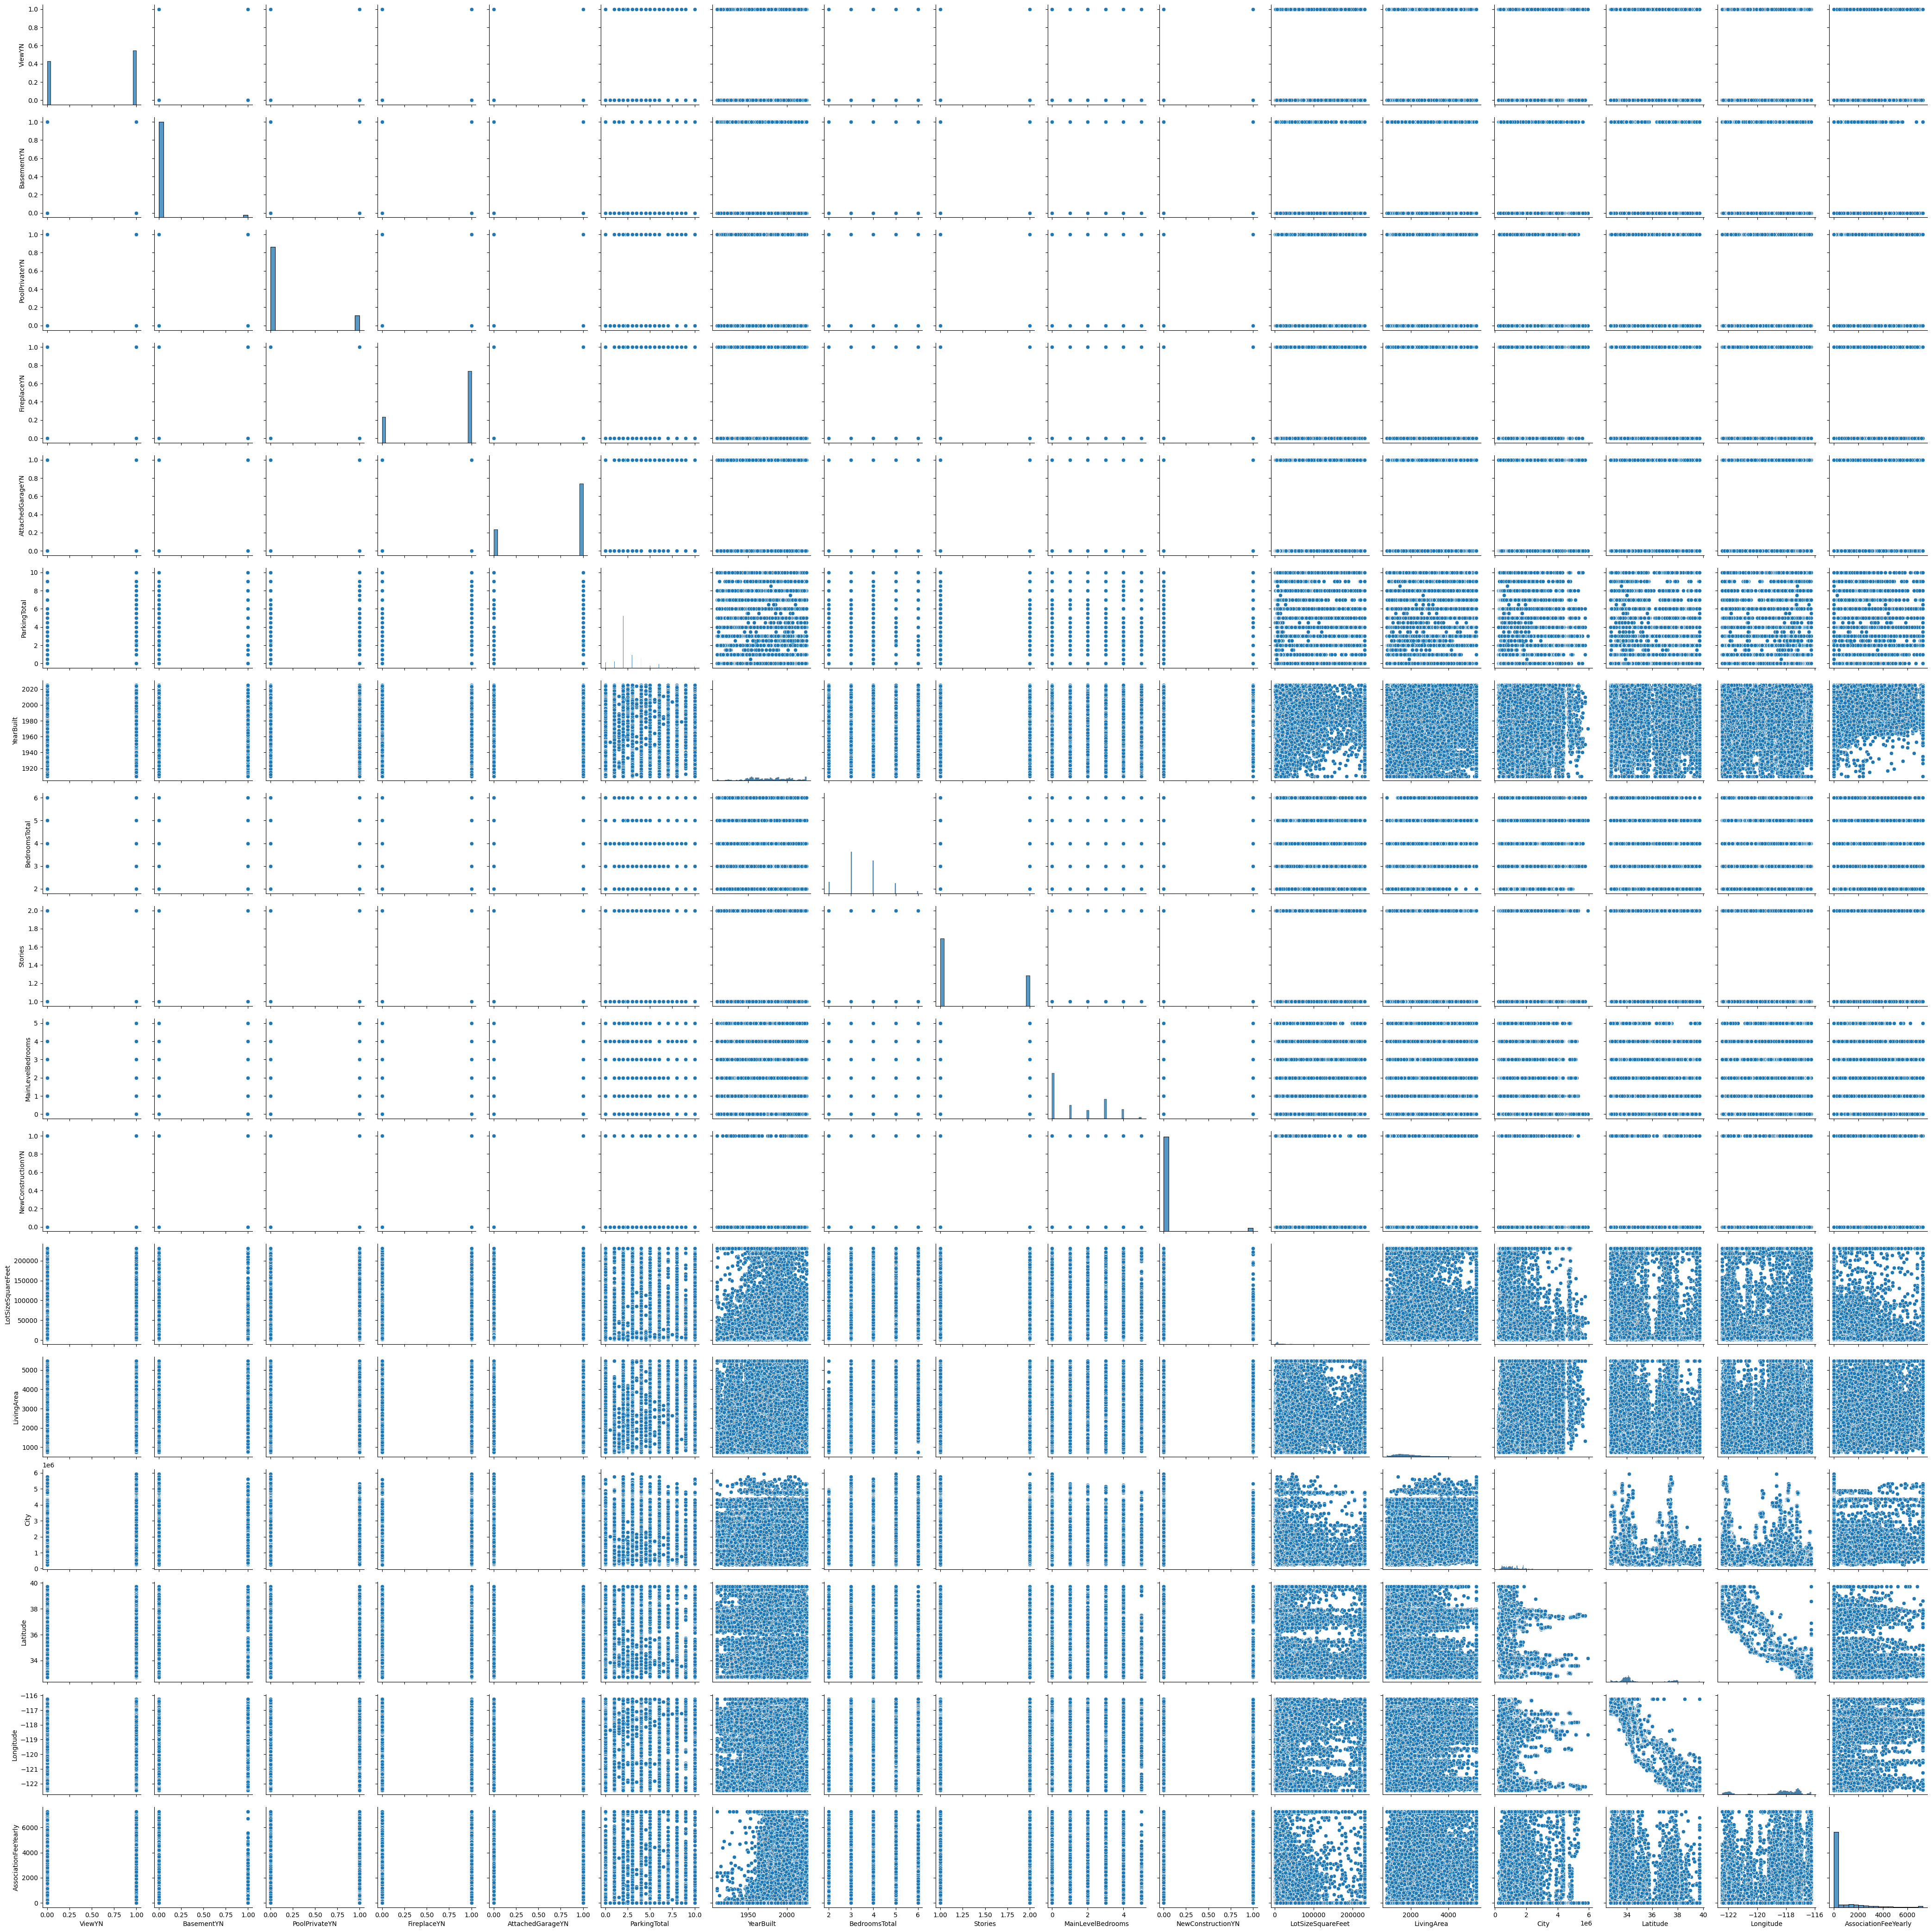

In [3]:
# creates a visual of the pairwise relationships in the training data

sns.pairplot(training_x)
plt.show()

In [4]:
# summary of the baseline model performance
# uses statsmodels to show a more cohesive summary of the regression results

stats_lm = smf.ols(formula='training_y ~ training_x', data=training_data).fit()
print(stats_lm.summary())

                            OLS Regression Results                            
Dep. Variable:             training_y   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                 2.230e+04
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:38:13   Log-Likelihood:            -1.6085e+06
No. Observations:              111204   AIC:                         3.217e+06
Df Residuals:                  111186   BIC:                         3.217e+06
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept      -6.001e+06    2.8e+05    -21.

In [5]:
# uses scikit-learn's LinearRegression to create the model
lm = LinearRegression()
lm.fit(training_x, training_y)

train_pred = lm.predict(training_x)
r2 = r2_score(training_y, train_pred)
print(r2)

test_pred = lm.predict(test_x)
r2_test = r2_score(test_y, test_pred)
print(r2_test)

0.7732319491094815
0.008772166954465366


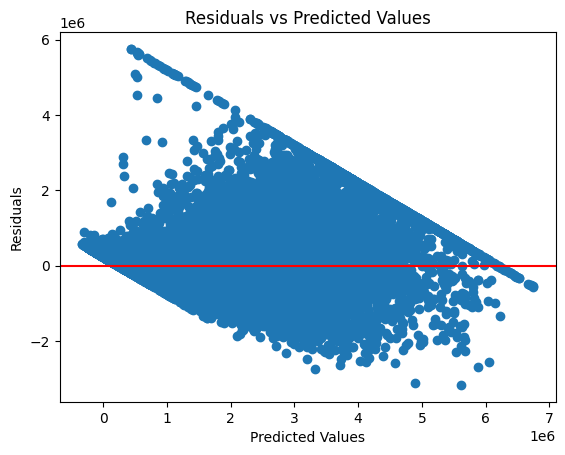

In [6]:
residuals = training_y - train_pred
plt.scatter(train_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.show()

In [7]:
# obtains the VIF of every feature

vif_data = pd.DataFrame()
vif_data["feature"] = training_x.columns
vif_data["VIF"] = [variance_inflation_factor(training_x.values, i) for i in range(training_x.shape[1])]
vif_data

,feature,VIF
0,ViewYN,2.641677
1,BasementYN,1.071979
2,PoolPrivateYN,1.359399
3,FireplaceYN,4.525960
4,AttachedGarageYN,4.868422
5,ParkingTotal,3.997089
6,YearBuilt,6471.860290
7,BedroomsTotal,34.723020
8,Stories,13.314007
9,MainLevelBedrooms,2.501909


In [12]:
training_x2 = training_x.copy()
training_x2 = training_x2.drop(columns=["YearBuilt"])

stats_lm_v2 = smf.ols(formula='training_y ~ training_x2', data=training_data).fit()
print(stats_lm_v2.summary())

                            OLS Regression Results                            
Dep. Variable:             training_y   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                 2.361e+04
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:42:39   Log-Likelihood:            -1.6087e+06
No. Observations:              111204   AIC:                         3.217e+06
Df Residuals:                  111187   BIC:                         3.218e+06
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -9.252e+06   2.13e+05    -